In [ ]:
from warnings import warn

try:
    import google.colab
    !pip install -Uq gemlib
except:
    warn("Not running in Colab, make sure `gemlib` is installed locally")

In [17]:
import jax
import gemlib
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import pandas as pd
import tensorflow_probability.substrates.jax as tfp
import xarray as xr
import scipy as sp

from scipy import stats
from typing import NamedTuple
from jax.typing import ArrayLike
from gemlib.deterministic import ode_model
from gemlib.distributions import DiscreteTimeStateTransitionModel
from gemlib.mcmc import mcmc, rwmh, adaptive_rwmh, hmc

%matplotlib inline
tfd = tfp.distributions

DTYPE=np.float64

sns.set_theme()

In [ ]:
# --- Season Boundaries ---

def get_season_boundaries(start_year, n_seasons, burn_in_seasons):

    """
    Calculate the day boundaries of influenza seasons.

    Each season runs from Monday of ISO week 40 to the start of week 40 in the following year.

    Parameters:
        start_year        : Calendar year in which the first *observed* season starts.
        n_seasons         : Number of observed seasons.
        burn_in_seasons   : Number of preceding seasons simulated as burn-in.

    Returns:
        season_boundaries : Array of the season boundaries (days) since the start of the simulation.
                            Includes the initial boundary and final endpoint.
    """

    first_year = start_year - burn_in_seasons    # first year of whole simulation

    # Find Monday W40 for each season inc. final endpoint
    season_starts = [pd.Timestamp.fromisocalendar(year, 40, 1)
                     for year in range(first_year, start_year + n_seasons + 1)]

    # Convert calendar dates into days since the first day
    season_boundaries = np.array([(date - season_starts[0]).days
                                   for date in season_starts])

    return season_boundaries

# -----

In [18]:
# --- ODE Model ---

# Incidence Matrix Setup
# - Compartments: S, E, I, R
# - Transitions: S -> E, E -> I, I -> R, R -> S
incidence_matrix = np.array([
    [-1,  0,  0,  1],  # S
    [ 1, -1,  0,  0],  # E
    [ 0,  1, -1,  0],  # I
    [ 0,  0,  1, -1]   # R
], dtype=DTYPE)

# Initial State
initial_state = np.array([[999, 0, 1, 0]], dtype=DTYPE)
popsize = 1000

# Season Boundaries
n_season = 3
n_burn_in_season = 20
season_bounds = get_season_boundaries(2012, n_season, n_burn_in_season)


def seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase):    # num steps not as an argument

    def se_rate(t, state):
        seasonal_term = amp * jnp.cos(2 * np.pi * t / 365 - phase)
        beta_t = beta * jnp.exp(seasonal_term)
        return beta_t * state[:, 2] / state.sum(axis=-1)

    def ei_rate(t, state):
        return sigma

    def ir_rate(t, state):
        return gamma

    def rs_rate(t, state):
        return omega

    return ode_model(transition_rate_fn = [se_rate, ei_rate, ir_rate, rs_rate],
                     initial_state = initial_state,
                     incidence_matrix = incidence_matrix,
                     num_steps = season_bounds[-1],
                     initial_time = 0.0,
                     time_delta = 1.0,
                     solver_kwargs = {"rtol": 1e-8, "atol": 1e-14})

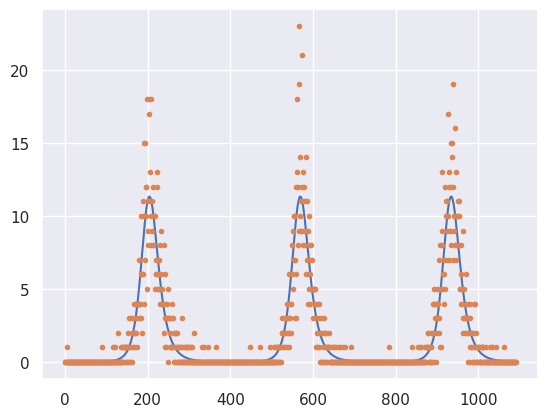

In [ ]:
# Fake Data
sigma = 0.5
alpha = 1
seirs_sim = seirs_beta_t_ode_model(beta=0.3, sigma=sigma, gamma=0.2, omega=1/180, amp=-0.2, phase=0)

times_burn = seirs_sim.times[season_bounds[n_burn_in_season]:]
states_burn = seirs_sim.states[season_bounds[n_burn_in_season]:]

sim_df = pd.DataFrame({
    "time": times_burn - season_bounds[n_burn_in_season],
    "S": states_burn[:, 0, 0],
    "E": states_burn[:, 0, 1],
    "I": states_burn[:, 0, 2],
    "R": states_burn[:, 0, 3]
})

cases = sigma * sim_df["E"]
np.random.seed(123)
obs_cases = np.random.poisson(lam = alpha * cases)

plt.plot(sim_df["time"], cases)
plt.plot(sim_df["time"], obs_cases, '.')

# -----

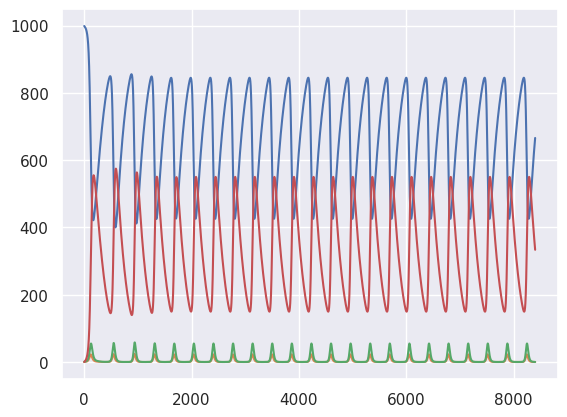

In [ ]:
plt.plot(seirs_sim.states[:,0,:])

In [ ]:
# --- Model Function ---

@tfd.JointDistributionCoroutineAutoBatched
def model():

# - Priors:
    beta = yield tfd.Gamma(
        concentration=DTYPE(1.0), rate=DTYPE(1.0/0.3), name="beta"
    )
    # sigma = yield tfd.Gamma(
    #     concentration=DTYPE(1.0), rate=DTYPE(2.0), name="sigma"
    # )
    sigma = 0.5
    gamma = 0.2
    # omega = yield tfd.Gamma(
    #     concentration=DTYPE(1.0), rate=DTYPE(180.0), name="omega"
    # )
    omega = 1/180.0
    amp = -0.2
    phase = 0

# - Model
    seirs = seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase)

    states_burn = seirs.states[season_bounds[n_burn_in_season]:]

    lmda = alpha * sigma * states_burn[:, 0, 1]    # alpha * sigma * E

    yield tfd.Poisson(rate = lmda, name = "obs_cases")
# -----

In [ ]:
pinned_model = model.experimental_pin(obs_cases=obs_cases)

In [ ]:
pinned_model.log_prob(beta=0.3) #, omega=1/180.0)

Array(-951.26499639, dtype=float64)

In [ ]:
init_pos = pinned_model.sample_unpinned(seed=jax.random.key(456))

In [ ]:
init_pos

StructTuple(
  beta=Array(0.24126526, dtype=float64)
)

In [ ]:
test = seirs_beta_t_ode_model(beta=init_pos.beta, sigma=0.5, gamma=0.2, omega=0.001, amp=-0.2, phase=0)
# test = seirs_beta_t_ode_model(beta=init_pos.beta, sigma=0.5, gamma=0.2, omega=init_pos.omega, amp=-0.2, phase=0)

In [ ]:
0.5*np.min(test.states[1:,0,1])

Array(8.81203973e-14, dtype=float64)

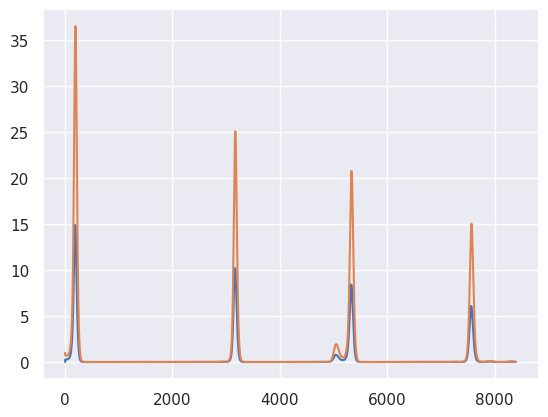

In [ ]:
plt.plot(test.states[:,0,1:3])

In [33]:
kernel = adaptive_rwmh(initial_scale=0.1)

In [15]:
samples, info = mcmc(
    num_samples=10000,
    sampling_algorithm=kernel,
    target_log_density_fn=pinned_model.log_prob,
    initial_position=init_pos,
    seed=jax.random.key(101)
)

_ = jax.block_until_ready(samples)

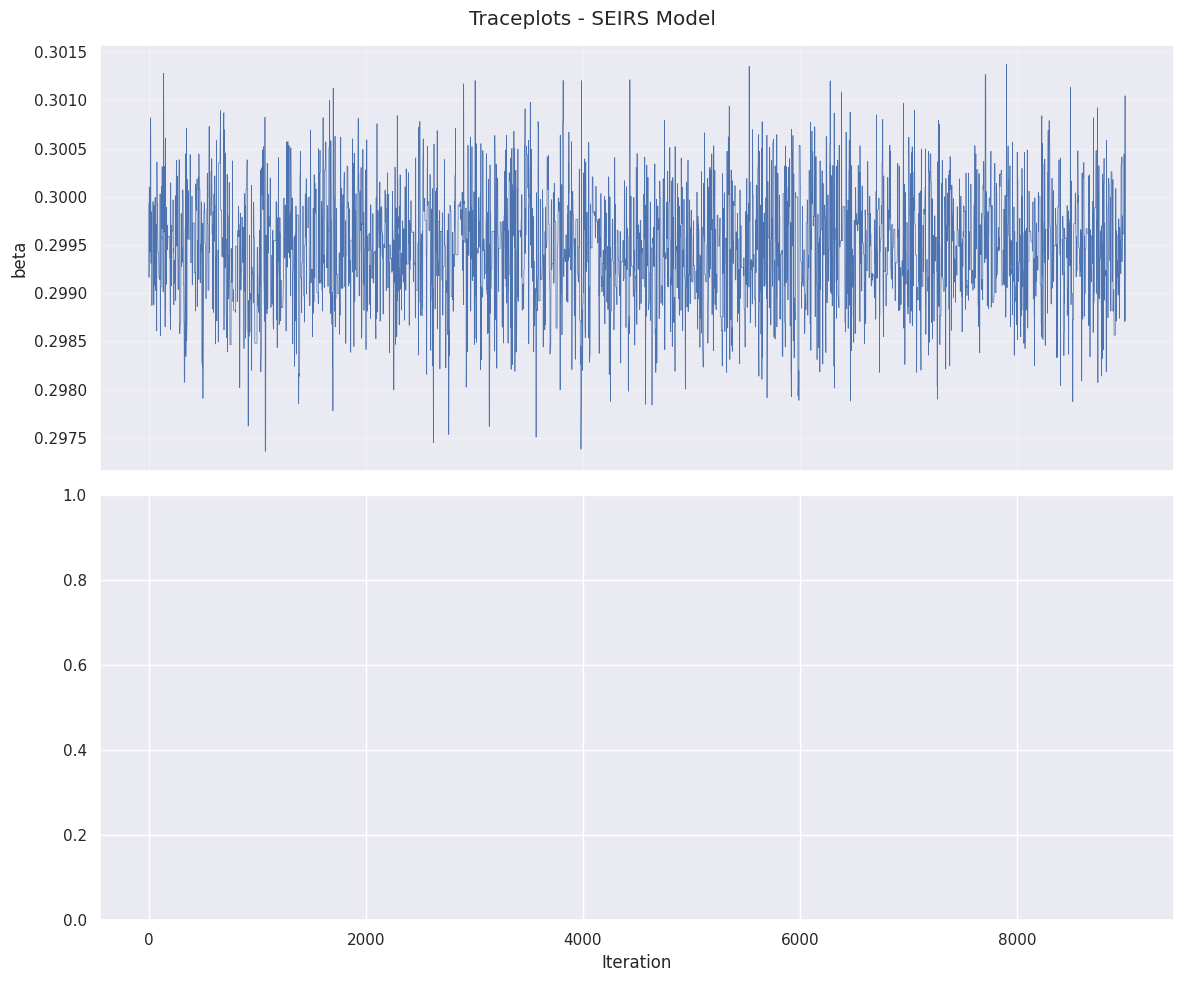

In [45]:
parameter_names = ["beta"] #, "omega"]

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for s, n, a in zip(samples, parameter_names, axes):
    a.plot(s[1000:], linewidth=0.5)
    a.set_ylabel(n)
    a.grid(alpha=0.3)

axes[-1].set_xlabel("Iteration")

plt.suptitle("Traceplots - SEIRS Model")
plt.tight_layout()
plt.show()

In [19]:
import time

omega_values = [0.001, 0.00556, 0.01, 0.05, 0.1]

for omega_test in omega_values:

    start = time.time()

    result = seirs_beta_t_ode_model(
        beta=0.3,
        sigma=0.5,
        gamma=0.2,
        omega=omega_test,
        amp=-0.2,
        phase=0
    )

    result.states.block_until_ready()

    print(
        f"Omega: {omega_test:.5f}, "
        f"Time: {time.time() - start:.4f}s"
    )

Omega: 0.00100, Time: 1.2961s
Omega: 0.00556, Time: 0.5730s
Omega: 0.01000, Time: 0.5931s
Omega: 0.05000, Time: 0.6493s
Omega: 0.10000, Time: 1.0241s


In [20]:
# --- Model Function ---

@tfd.JointDistributionCoroutineAutoBatched
def model2():

# - Priors:
    beta = yield tfd.Gamma(
        concentration=DTYPE(1.0), rate=DTYPE(1.0/0.3), name="beta"
    )
    # sigma = yield tfd.Gamma(
    #     concentration=DTYPE(1.0), rate=DTYPE(2.0), name="sigma"
    # )
    sigma = 0.5
    gamma = 0.2
    omega = yield tfd.Gamma(
        concentration=DTYPE(1.0), rate=DTYPE(180.0), name="omega"
    )
    # omega = 1/180.0
    amp = -0.2
    phase = 0

# - Model
    seirs = seirs_beta_t_ode_model(beta, sigma, gamma, omega, amp, phase)

    states_burn = seirs.states[season_bounds[n_burn_in_season]:]

    lmda = alpha * sigma * states_burn[:, 0, 1]    # alpha * sigma * E

    yield tfd.Poisson(rate = lmda, name = "obs_cases")
# -----

In [21]:
pinned_model2 = model2.experimental_pin(obs_cases=obs_cases)

In [22]:
pinned_model2.log_prob(beta=0.3, omega=1/180.0)

Array(-947.07203954, dtype=float64)

In [23]:
for omega in omega_values:
    lp = pinned_model2.log_prob(
        beta=0.3,
        omega=omega
    )
    print(omega, lp)

0.001 -22224.927790413836
0.00556 -947.2547004235057
0.01 -3682.9211563890053
0.05 -10277.50090426803
0.1 -17153.525471461737


In [24]:
omega_prior = tfd.Gamma(
    concentration=DTYPE(1.0),
    rate=DTYPE(180.0)
)

print(omega_prior.log_prob(0.001))

5.012956850890211


In [25]:
omega_test = 0.001
beta_test = 0.3

seirs = seirs_beta_t_ode_model(
    beta_test, 0.5, 0.2, omega_test, -0.2, 0
)
states = seirs.states[season_bounds[n_burn_in_season]:]
E = states[:, 0, 1]
lmda = alpha * 0.5 * E

In [26]:
np.min(E)

Array(3.5182234e-09, dtype=float64)

In [27]:
print("States finite:", jnp.all(jnp.isfinite(states)))
print("E finite:", jnp.all(jnp.isfinite(E)))
print("Rate finite:", jnp.all(jnp.isfinite(lmda)))
print("Rate minimum:", jnp.min(lmda))
print("Rate maximum:", jnp.max(lmda))

States finite: True
E finite: True
Rate finite: True
Rate minimum: 1.7591116990541358e-09
Rate maximum: 5.6590771671650755


In [28]:
obs_lp = tfd.Poisson(rate=lmda).log_prob(obs_cases)
print("Poisson log-prob finite:", jnp.all(jnp.isfinite(obs_lp)))
print("Poisson log-prob contains NaN:", jnp.any(jnp.isnan(obs_lp)))

print("Beta prior:", tfd.Gamma(1., 1./0.3).log_prob(beta_test))
print("Omega prior:", tfd.Gamma(1., 180.).log_prob(omega_test))

Poisson log-prob finite: True
Poisson log-prob contains NaN: False
Beta prior: 0.20397282
Omega prior: 5.012957


In [29]:
init_pos2 = pinned_model2.sample_unpinned(seed=jax.random.key(456))

In [30]:
init_pos2

StructTuple(
  beta=Array(0.24126526, dtype=float64),
  omega=Array(0.01003378, dtype=float64)
)

In [31]:
from gemlib.mcmc import transform_sampling_algorithm

tfb = tfp.bijectors

In [ ]:
# kernel2 = adaptive_rwmh(initial_scale=0.0001)

In [34]:
kernel2 = transform_sampling_algorithm(
    bijectors=[tfb.Exp()]*2,
    sampling_algorithm=adaptive_rwmh(
        initial_scale=0.1
  )
)

In [42]:
samples2, info2 = mcmc(
    num_samples=10000,
    sampling_algorithm=kernel2,
    target_log_density_fn=pinned_model2.log_prob,
    initial_position=init_pos2,
    seed=jax.random.key(101)
)

_ = jax.block_until_ready(samples2)

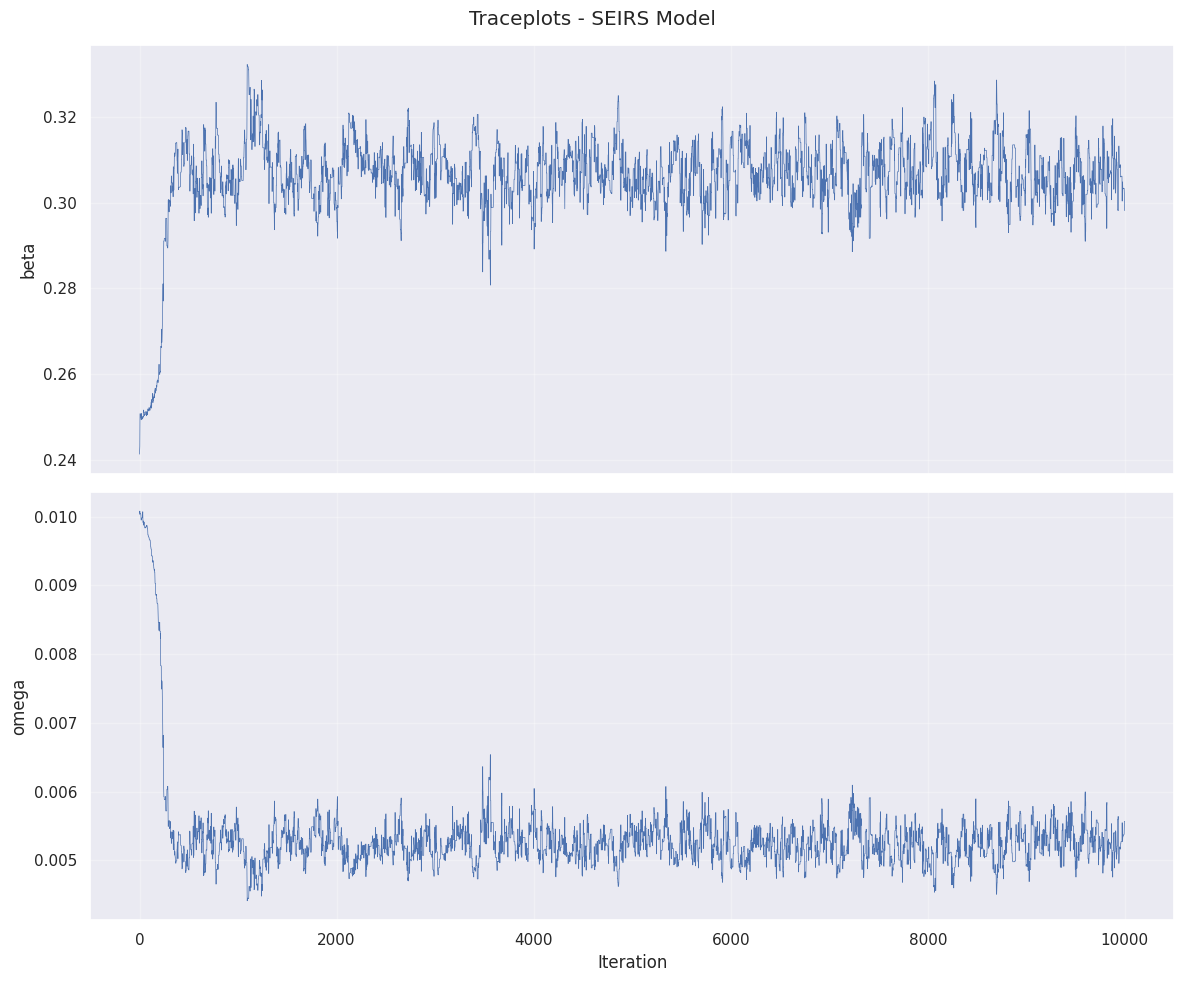

In [43]:
parameter_names = ["beta", "omega"]

fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

for s, n, a in zip(samples2, parameter_names, axes):
    a.plot(s, linewidth=0.5)
    a.set_ylabel(n)
    a.grid(alpha=0.3)

axes[-1].set_xlabel("Iteration")

plt.suptitle("Traceplots - SEIRS Model")
plt.tight_layout()
plt.show()

In [47]:
print(np.sum(info.is_accepted)/10000)

0.2897
